# Plug flow reactor simulation for PFOA thermal degradation

Uses a Lagrangian particle approach with an ExtensibleIdealGasConstPressureMoleReactor.
The temperature profile T(x) is imposed via the extensible reactor API, overriding the
energy equation RHS. Position x is added as an extra state variable with dx/dt = u.

The temperature profile is a sum of Gaussians fitted to the experimental data from
Weber et al., parameterized by the nominal furnace temperature.



In [1]:
import pandas as pd
import os
import re
import matplotlib
import cantera as ct
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

In [2]:
ct.__version__

'3.2.0'

Temperature profile: T(x_cm, nominal_C) -> T in °C
Fitted sum of 5 Gaussians (ODR fit from gaussian_fit_temperature_profiles.py)
x in cm, nominal in °C, returns °C

In [3]:
# Parameters from the ODR fit
_BASELINE = 21.9537   # °C
_A1 = 1.942512;  _B1 = 925.0228;  _MU1 = 11.9773;  _SIGMA1 = 3.9644
_A2 = 0.630055;  _B2 = 0.0000;    _MU2 = 4.3965;   _SIGMA2 = 4.0971
_A3 = 0.343392;  _B3 = 447.7876;  _SIGMA3 = 10.7594
_MIDPOINT = 30.0  # cm

def T_profile_celsius(x_cm, nominal_C):
    """Temperature profile in °C, given position in cm and nominal temp in °C."""
    x = x_cm
    nom = nominal_C
    mid = _MIDPOINT
    return (_BASELINE
        + _A1 * max(nom - _B1, 0) * np.exp(-0.5 * ((x - (mid - _MU1)) / _SIGMA1)**2)
        + _A1 * max(nom - _B1, 0) * np.exp(-0.5 * ((x - (mid + _MU1)) / _SIGMA1)**2)
        + _A2 * max(nom - _B2, 0) * np.exp(-0.5 * ((x - (mid - _MU2)) / _SIGMA2)**2)
        + _A2 * max(nom - _B2, 0) * np.exp(-0.5 * ((x - (mid + _MU2)) / _SIGMA2)**2)
        + _A3 * max(nom - _B3, 0) * np.exp(-0.5 * ((x - mid) / _SIGMA3)**2)
    )

def T_profile_K(x_m, nominal_C):
    """Temperature in K, given position in m and nominal temp in °C."""
    x_cm = x_m * 100.0  # m -> cm
    return T_profile_celsius(x_cm, nominal_C) + 273.15

def T_average_K(nominal_C):
    """Temperature in K averaged over the reactor length, given nominal temp in °C.
    
    But weight it differently, so that it gets the RTD better.
    do 1/(mean of 1/T) instead of mean of T
    """

    return 1/(np.mean([1/T_profile_K(x, nominal_C) for x in np.linspace(0, _MIDPOINT*2, 100)]))



def dTdx_K_per_m(x_m, nominal_C):
    """Analytical dT/dx in K/m, given position in m and nominal temp in °C.

    Each Gaussian term a * coeff * exp(-0.5*((x_cm - c)/s)^2) contributes
    dT/dx_cm = a * coeff * [-(x_cm - c)/s^2] * exp(-0.5*((x_cm - c)/s)^2)

    Then dT/dx_m = dT/dx_cm * 100 (chain rule: dx_cm/dx_m = 100)
    and the °C -> K conversion doesn't affect the derivative.
    """
    x_cm = x_m * 100.0
    dTdx_cm = 0.0

    if nominal_C > _B1:
        # Outer pair
        coeff = _A1 * (nominal_C - _B1)
        z = (x_cm - (_MIDPOINT - _MU1)) / _SIGMA1
        dTdx_cm += coeff * (-z / _SIGMA1) * np.exp(-0.5 * z*z)
        z = (x_cm - (_MIDPOINT + _MU1)) / _SIGMA1
        dTdx_cm += coeff * (-z / _SIGMA1) * np.exp(-0.5 * z*z)

    if nominal_C > _B2:
        # Inner pair
        coeff = _A2 * (nominal_C - _B2)
        z = (x_cm - (_MIDPOINT - _MU2)) / _SIGMA2
        dTdx_cm += coeff * (-z / _SIGMA2) * np.exp(-0.5 * z*z)
        z = (x_cm - (_MIDPOINT + _MU2)) / _SIGMA2
        dTdx_cm += coeff * (-z / _SIGMA2) * np.exp(-0.5 * z*z)

    if nominal_C > _B3:
        # Center
        coeff = _A3 * (nominal_C - _B3)
        z = (x_cm - _MIDPOINT) / _SIGMA3
        dTdx_cm += coeff * (-z / _SIGMA3) * np.exp(-0.5 * z*z)

    # Convert cm -> m: dT/dx_m = dT/dx_cm * (dx_cm / dx_m) = dT/dx_cm * 100
    return dTdx_cm * 100.0


## Extensible Reactor: 
imposed T(x) profile with x as a state variable


In [4]:
class PFR_Reactor(ct.ExtensibleIdealGasConstPressureMoleReactor):
    """Lagrangian particle reactor with imposed temperature profile T(x).

    Extra state variable: x (position in m).
    The energy equation RHS is overwritten to impose dT/dt = dT/dx * u.
    An additional equation dx/dt = u is added.
    """

    def __init__(self, *args, nominal_temp_C, mass_flow_rate, cross_section_area,
                 **kwargs):
        super().__init__(*args, **kwargs)
        self.nominal_temp_C = nominal_temp_C
        self.mass_flow_rate = mass_flow_rate      # kg/s (constant)
        self.cross_section_area = cross_section_area  # m^2 (constant)
        self.position = 0.0  # current position in m

    def after_initialize(self, t0):
        """Called after initialize. Register extra state variable."""
        if t0 != 0:
            raise ValueError(f"Expected initialization time t0=0, got t0={t0}")
        # Add one extra equation for position x
        self.n_vars += 1
        self.i_position = self.n_vars - 1
        self.position = 0.0

    def after_get_state(self, y):
        """Append x to the state vector."""
        y[self.i_position] = self.position

    def after_update_state(self, y):
        """Read x back from the state vector."""
        self.position = y[self.i_position]

    def before_component_index(self, name):
        # Other components are handled by the method from the base Reactor class
        if name == 'position':
            return self.i_position

    def before_component_name(self, i):
        # Other components are handled by the method from the base Reactor class
        if i == self.i_position:
            return 'position'


    def after_eval(self, t, LHS, RHS):
        """Modify the RHS to impose the temperature profile and add dx/dt = u."""
        # Current position from the state
        x_m = self.position

        # Current velocity: u = mdot / (rho * A)
        velocity = self.mass_flow_rate / (self.density * self.cross_section_area)

        # Impose dT/dt = dT/dx * u
        dTdx = dTdx_K_per_m(x_m, self.nominal_temp_C)
        dTdt = dTdx * velocity

        # Temperature is state variable index 0 for IdealGasConstPressureMoleReactor
        # The governing eq is: LHS[0] * dT/dt = RHS[0]
        # So to impose our dT/dt: RHS[0] = LHS[0] * dT/dt
        RHS[0] = LHS[0] * dTdt

        # Extra equation for position: dx/dt = u
        # LHS for extra variables defaults to 1.0, so RHS = dx/dt = u
        RHS[self.i_position] = velocity


## Simulation parameters
(Weber et al. experiments)


In [5]:
# Reactor geometry
int_diam = 0.007       # m (7 mm ID)
radius = int_diam / 2
cross_area = np.pi * radius * radius  # m^2

# Flow conditions
Vdot = 150e-6 / 60.0  # volumetric flow rate: 150 mL/min -> m^3/s (at room T?)

# Reactor length
length = 0.60  # m (60 cm)

# Nominal furnace temperatures to simulate (°C)
nominal_temperatures = [400, 500, 600, 700, 800, 900, 1000, 1100]
nominal_temperatures = np.arange(400, 1101, 25)
#nominal_temperatures = np.arange(400, 1101, 50)

## Diagnostic tools

In [6]:
def plot_rates_of_progress(gas, top_n=3, show=True, verbose=True):
    """Plot forward (blue) and reverse (red) rates of progress for all reactions."""
    # Plot forward and reverse rates
    plt.semilogy(gas.forward_rates_of_progress, 'b.', label='Forward')
    plt.semilogy(gas.reverse_rates_of_progress, 'r.', label='Reverse')

    # Label highest forward and reverse rates
    top_forward = np.argsort(gas.forward_rates_of_progress)[-top_n:]
    top_reverse = np.argsort(gas.reverse_rates_of_progress)[-top_n:]
    for idx in top_forward:
        plt.text(idx, gas.forward_rates_of_progress[idx], f'R{idx}', color='blue', fontsize=8)
        if verbose:
            print(
                f"R{idx}: {gas.reaction(idx).equation}  "
                f"Forward ROP: {gas.forward_rates_of_progress[idx]:.3e}"
            )
    for idx in top_reverse:
        plt.text(idx, gas.reverse_rates_of_progress[idx], f'R{idx}', color='red', fontsize=8)
        if verbose:
            print(
                f"R{idx}: {gas.reaction(idx).equation}  "
                f"Reverse ROP: {gas.reverse_rates_of_progress[idx]:.3e}"
            )
    max_rop = max(max(gas.forward_rates_of_progress), max(gas.reverse_rates_of_progress))
    tenth_top = sorted(list(gas.forward_rates_of_progress) + list(gas.reverse_rates_of_progress))[-10]
    plt.ylim(tenth_top/1e10, max_rop*10)
    plt.xlabel('Reaction')
    plt.ylabel('Rate of Progress')
    plt.title('Rates of Progress for All Reactions')
    plt.legend()
    if show:
        plt.show()

def find_culprit_reactions(gas, species_index=None, species_name=None):
    """Find the top reactions contributing to the net production/consumption of a species."""
    if species_index is not None:
        k = species_index
    elif species_name is not None:
        k = gas.species_index(species_name)
    else:
        raise ValueError("Either species_index or species_name must be provided")

    # Stoich coefficients for species k across all reactions
    nu = gas.product_stoich_coeffs[k, :] - gas.reactant_stoich_coeffs[k, :]
    
    # Absolute total rate
    rop = abs(gas.forward_rates_of_progress) + abs(gas.reverse_rates_of_progress)
    
    # Contribution of each reaction to species k
    contrib = nu * rop
    
    # Sort by magnitude
    top = np.argsort(np.abs(contrib))[::-1][:8]
    
    print(f"\nTop reactions affecting {gas.species_name(k)}:")
    for idx in top:
        if contrib[idx] != 0:
            print(f"  R{idx}: {gas.reaction(idx).equation}  "
                  f"(rate contribution: {contrib[idx]:.4e})")


# Run simulations

In [7]:
def color_for_temperature(value, min_temp=400, max_temp=1100):
    color_map = plt.get_cmap('plasma')
    clipped_value = np.clip(value, min_temp, max_temp)
    normalized = (clipped_value - min_temp) / (max_temp - min_temp)
    return color_map(normalized)

def get_experiment_data(exp_label):
        
    spec_data=pd.read_csv(f'../../../literature_data/{exp_label}.csv')
        
    exp_data = {}
    for header in ['model', 'experiments', 'error']:
        index_of_x = spec_data.columns.get_loc(header)
        index_of_y = index_of_x+1 

        x_values_raw = spec_data.iloc[:, index_of_x]
        x_values = [float(x) for x in x_values_raw[1:]] #removes first header of 'X' or 'Y'
    
        y_values_raw = spec_data.iloc[:, index_of_y]
        y_values = [float(x) for x in y_values_raw[1:]]
        
        exp_data[header]=(x_values, y_values)
        
        
    return exp_data

def get_raw_data_150mLmin(spec): 
    """retrieve the raw data, given via an excel sheet from Weber. Inital concentrations in excel sheet: PFOA 402 ppm.  """
    init_PFOA = 402
    
    exp_temp = [400, 425, 450, 500, 550, 575, 630, 660, 690, 720, 765, 800, 835, 875, 910, 975, 1000] #experimental measurements do not include 475
    
    HF_conc = [0, 0, 3.02, 49.47, 149.8, 221.17, 290.88, 467.82, 762.73, 1433, 1671, 1756, 1868, 1888, 1910, 1922, 1931] #double checked
    COF2_conc = [0, 0, 0, 0, 0, 0, 7.28, 11.44, 15.13, 17.21, 32.82, 188.28, 333.53, 565.88, 667.69, 677.92, 680.17] #double checked
    CO2_conc = [0, 0, 1.09, 24.82, 47.31, 61.37, 142, 301, 416, 569, 612.45, 706.13, 804.46, 815, 822, 827, 838] #double checked
    CO_conc = [0, 0, 0, 6.12, 9.82, 11.27, 19.89, 62.25, 202.36, 301.08, 410, 486, 580, 610, 640, 670, 690] #double checked
    C2F6_conc = [0, 0, 0, 0, 0, 0, 8.7, 11.5, 15.3, 21.2, 98.23, 226, 268.87, 301, 322, 366, 371] #double checked
    C2F4_conc = [0, 0, 0, 0, 0, 0, 1.76, 13.36, 36.59, 60.28, 58.33, 10.36, 0, 0, 0, 0, 0] #double checked 
    CF4_conc = [0, 0, 0, 0, 0, 0, 1.2, 1.59, 2.43, 2.94, 4.69, 11.07, 26.27, 52.85, 78.85, 100, 110] #double checked
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (exp_temp, conc_ratio_dict[spec])


def get_raw_data_50mLmin(spec): #this is for a plot in the SI 
    """retrieve the raw data, given via an excel sheet from Weber. Initial concentrations in excel sheet: PFOA 467 ppm, H2O 750 ppm"""
    init_PFOA = 467 #ppm 
    
    approx_temp = [390, 410, 440, 510, 540, 570, 615, 660, 710, 765, 800, 835, 875, 910, 975, 1000] #double checked
    
    HF_conc = [0, 0, 10, 233, 280, 450, 617, 864, 1027, 1274, 1459, 1525, 1623, 1658, 1666, 1721] #double checked
    COF2_conc = [0, 0, 0, 0, 31, 132, 173, 214, 226, 409, 620, 647, 722, 711, 709, 710] #double checked
    CO2_conc = [1, 8, 31, 75, 161, 254, 276, 336, 502, 1249, 1499, 1578, 1627, 1602, 1522, 1515] #double checked
    CO_conc = [0, 5, 31, 27, 48, 211, 283, 378, 435, 502, 517, 712, 798, 830, 830, 848]
    C2F6_conc = [0, 0, 0, 4, 6, 7, 16, 62, 88, 138, 208, 313, 286, 242, 211, 126]
    C2F4_conc = [0, 0, 0, 0, 0, 0, 4, 15, 31, 73, 61, 42, 21, 16, 0, 0]
    CF4_conc = [0, 0, 0, 3, 2, 2, 2, 2, 2, 3, 48, 156, 201, 242, 248, 279]
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (approx_temp, conc_ratio_dict[spec])


def get_exit_concentration_ratio(results, species_of_interest, weber=False):
    # find concentration along the reactor
    exit_concentrations = []
    nominal_temps_to_plot = []
    for nominal_T_C in nominal_temperatures:
        r = results[nominal_T_C]
        states = r['states']
        if species_of_interest in states.species_names:
            idx = states.species_index(species_of_interest)
            if weber: 
                PFOA_idx = states.species_index('PFOA')
            else:
                PFOA_idx = states.species_index('PFOA(36)')
            spec_conc = states.concentrations[:, idx]
            PFOA_conc = states.concentrations[:, PFOA_idx]
            concentration_ratio = spec_conc[-1]/PFOA_conc[0]
            exit_concentrations.append(concentration_ratio)
            nominal_temps_to_plot.append(nominal_T_C)
    return exit_concentrations, nominal_temps_to_plot



def edit_the_gas(gas_full, include_these_reactions = None, exclude_species=None, exclude_reactions_involving = None): 
    """exclude_reactions_involving: list of lists of species names involved in each reaction that we would like to exclude.
       include_these_reactions: yaml string or dictionary that can be passed into Cantera's ct.Reaction.from_yaml(yaml_string, gas)
       exclude_species: list of species names to exclude. Will also remove all reactions that involve excluded species. 
    """
  
    all_species = gas_full.species()
    
    
    #exclude specified species
    if exclude_species: 
        species = []
        for S in all_species: 
            if S.name in exclude_species:
                print(f'excluding species {S.name}')
                continue #skipping this one
            species.append(S)
    else: 
        species = all_species
                                   
    species_names = {S.name for S in species}


    all_reactions = gas_full.reactions()
    print(f'Gas (full) previously had {len(all_reactions)} reactions.')
    reactions = []
    
    removed_reactions=0
    reaction_involved_excluded_species = 0 

    
    for R in all_reactions:
        add_in=True

        if exclude_species: 
            if any(spec in list(R.reactants.keys())+list(R.products.keys()) for spec in exclude_species):
                add_in=False
                reaction_involved_excluded_species+=1
                print(f'Includes excluded species, removing: {R}.')
        
        if exclude_reactions_involving:  
            for ind, species_list in enumerate(exclude_reactions_involving): 
                
                total_species_involved = list(R.reactants.values())+list(R.products.values())
                total_num_of_species_involved = np.array(total_species_involved).sum()
                
                
                if all(spec in R.equation for spec in species_list) and len(species_list)==total_num_of_species_involved:
                        print(f'excluding specified reaction: {str(R.equation)}')
                        add_in=False
            

        if add_in==True: 
            reactions.append(R)
        
        if add_in==False: 
            removed_reactions+=1
            

    if include_these_reactions: 
        for yaml_string in include_these_reactions: 
            new_reaction = ct.Reaction.from_yaml(yaml_string, gas_full)
            print(f'Adding in {new_reaction.equation}')
            reactions.append(new_reaction)
        
    print(f'Gas (small) now has {len(reactions)} reactions.')
    gas_small = ct.Solution(thermo='IdealGas', kinetics='GasKinetics',
                       species=species, reactions=reactions)
       
    return gas_small

In [8]:
##### variables for Weber mechanism
plot_concentration_ratios_weber = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model

initial_composition_weber = {"PFOA": 4.02e-4, #402 ppm of PFOA,
                    "H2O": 7.50e-4, #750 ppm of H2O(g) 
                    "O2": 0.20975808, #Total of trace species: 4.02e-4 + 7.50e-4 = 1.152e-3, Remaining fraction for air: 1 - 1.152e-3 = 0.998848, 21% O2, 79% N2
                    "N2": 0.78908992,
                    }    

axes_for_plotting_weber = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}



#### RMG mechanism ('/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech')
initial_composition ={"PFOA(36)": 4.02e-4, #402 ppm of PFOA,
                    "H2O(8)": 7.50e-4, #750 ppm of H2O(g) 
                    "O2(5)": 0.20975808, #Total of trace species: 4.02e-4 + 7.50e-4 = 1.152e-3, Remaining fraction for air: 1 - 1.152e-3 = 0.998848, 21% O2, 79% N2
                    "N2": 0.78908992,
                    }

plot_concentration_ratios = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)']

axes_for_plotting = {'HF(11)': [0,0],
                    'C2F4(64)': [0,1],
                    'CO2(13)': [0,2],
                    'C2F6(51)': [0,3],
                    'CO(12)': [1,0],
                    'CF4(23)': [1,1],
                    'COF2(25)': [1,2]}

exp_mapping = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}

# PFR Simulation

In [23]:
chemkins_to_convert = [324] #number of core species in chemkin file name. 

# exclude_reactions_involving = None


exclude_reactions_involving = [ ['O(2)', 'CHF2CF2(172)', 'OHr(7)', 'C2F4(64)'] ,
['FOH(185)', 'PFvinylr(102)', 'OHr(7)', 'C2F4(64)'] ,
['OHr(7)', 'C2F4(64)', 'CF2(t)(18)', 'CF2OHr(26)'] ,
['OHr(7)', 'C2F4(64)', 'HF(11)', 'PF2acylFr(96)'] ,
['OHr(7)', 'C2F4(64)', 'CF2(s)(17)', 'CF2OHr(26)'] ,
['OHr(7)', 'C2F4(64)', 'OC(F)(F)[C](F)F(355)'] ,
['OHr(7)', 'C2F4(64)', '[O]C(F)(F)C(F)F(1672)'] ,
['OHr(7)', 'C2F4(64)', 'CF2(s)(17)', 'CHF2O(157)'] ,
['OHr(7)', 'C2F4(64)', 'CF3O(175)', 'CHF(148)'] ,
['O(2)', 'CHF2CF2(172)', 'OHr(7)', 'C2F4(64)'] ,
['OHr(7)', 'C2F4(64)', 'F(3)', 'O=C(F)C(F)F(1239)'] ,
['OHr(7)', 'C2F4(64)', 'COF2(25)', 'CHF2r(20)'] ,
['OHr(7)', 'C2F4(64)', 'O[C](F)C(F)(F)F(506)'] ,
['OHr(7)', 'C2F4(64)', 'H(1)', 'PF2acylF(45)'] ,
['OHr(7)', 'C2F4(64)', 'OHr(7)', 'PF2alkyl(s)(115)'] ,
['OHr(7)', 'C2F4(64)', 'CF3r(19)', 'CFOH(155)'] ,
['OHr(7)', 'C2F4(64)', 'F2(6)', 'O=C(F)[CH]F(2923)']]

exclude_reactions_involving = [['PF3acylFr(97)', 'PF4alkylr(110)', 'PF7acylF(50)'],
                               ['CFOr(24)', 'O2(5)', 'CO(12)', '[O]OF(297)']]
                                
# exclude_reactions_involving = [#['C4HF7(630)', 'PF2alkylr(108)', 'C6HF12(3914)'],
#                                #['C4HF7(1408)', 'PF3alkylr(109)', 'C7HF14(2752)'],
#                                 ['C2F6(51)', 'C6HF9O2(273)', 'PFOA(36)'],
#                                # ['C8F14O(428)', 'C7F14(120)', 'CO(12)'],
#                                # C3F7(299),
#                               ]
# exclude_species=['C5F11O2(3174)', 'O2(298)', 'C2F4O(3285)'] # 'O2(298)', 'C2F4O(3285)',] #'OO[C](F)F(2616)'] #(6234) + O2 reaction may be eating up a bit of O2? #['C4F10(2265)', 'C7HF13O(709)' ]
exclude_species = ['C8F14O(428)']
include_these_reactions = None


#chemkins_to_convert = [300] #number of core species in chemkin file name. 
# chemkins_to_convert = list(range(200, 345, 5))

main_version = 'main' #'main_fg_in_XY_elim_hydroxyl' 
# full_path_main = f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/just_PFAS/skeleton_mech_comparison_to_main/{main_version}/chemkin'
#for saving the data 
results_for_all_chemkins = {}
results_for_weber = {}

initial_composition ={"PFOA(36)": 4.02e-4, #402 ppm of PFOA,
                    "H2O(8)": 7.50e-4, #750 ppm of H2O(g) 
                    "O2(5)": 0.20975808, #Total of trace species: 4.02e-4 + 7.50e-4 = 1.152e-3, Remaining fraction for air: 1 - 1.152e-3 = 0.998848, 21% O2, 79% N2
                    "N2": 0.78908992,
                    }


# for cn, edit_gas_flag in zip(chemkins_to_convert + [None], [False, True, False]): #run through all RMG chemkins we want, then do Weber's mech
for cn, edit_gas_flag in zip(chemkins_to_convert, [True]): #run through all RMG chemkins we want, then do Weber's mech
# for cn, edit_gas_flag in zip([None], [False]): #run through all RMG chemkins we want, then do Weber's mech

    if cn is not None: 
        weber_flag=False
    if cn is None: 
        weber_flag=True 
    
    if weber_flag==False: 
        #get the chemkin file name 
        if cn >= 100: 
            #yaml_file_name = f'chem0{cn}_manually_edited.yaml'
            # yaml_file_name = f'chem0{cn}.yaml'
            # yaml_file_name = f'{full_path_main}/chem0{cn}.yaml'
            yaml_file_name = f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0{cn}.yaml'
            # yaml_file_name = f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0325_homo_scission.yaml' 

        if cn < 100:
            # yaml_file_name = f'chem00{cn}.yaml'
            yaml_file_name = f'{full_path_main}/chem00{cn}.yaml'
        # mechanism_file = f'./chemkin/{yaml_file_name}'
        mechanism_file = yaml_file_name
        
        #or just directly define the mech file name
         # mechanism_file = <path_to_mech_file>
        print(f'******** Chemkin # {cn} ************')
    
    if weber_flag==True: 
        mechanism_file = '../../../../chemkin_for_Weber_2025_12_12/PFAS_O2_H2O_N2O_publish.yaml'
        print(f'******** Weber mech ************')
    
    print(mechanism_file)
    results = {}
    

    gas_full = ct.Solution(mechanism_file)
    print('Loaded gas_full')

    if edit_gas_flag==False: 
        gas = gas_full #there will be no editing of the Cantera gas object
        print('not editing gas')
    if edit_gas_flag==True:
        gas = edit_the_gas(gas_full, include_these_reactions = include_these_reactions, exclude_species=exclude_species, exclude_reactions_involving = exclude_reactions_involving)
        cn = str(cn)+'_edited' 
        print('using edited gas...')

    if weber_flag==False: 
        #we are dealing with the RMG mechanism 
        print('gas loaded successfully.')
        init_comp = initial_composition


    if weber_flag==True: 
        #we are dealing with the Weber mechanism
        print('gas loaded successfully.')
        init_comp = initial_composition_weber

    gas.TPX = 298.15, ct.one_atm, init_comp
    rho_inlet = gas.density
    mass_flow_rate = rho_inlet * Vdot
    
    for nominal_T_C in nominal_temperatures:
    
            
        print(f"\n{'='*60}")
        print(f"Simulating nominal temperature: {nominal_T_C} °C")
        print(f"{'='*60}")

        # Set up the gas at inlet conditions
        T_inlet_K = T_profile_K(0.0, nominal_T_C)
        gas.TPX = T_inlet_K, ct.one_atm, init_comp

        # print(f"  Inlet T: {T_inlet_K:.1f} K ({T_inlet_K - 273.15:.1f} °C)")
        # print(f"  Mass flow rate: {mass_flow_rate:.6e} kg/s")
        # print(f"  Inlet velocity (at 298.15K): {Vdot / cross_area:.4f} m/s")
        # print(f"  Inlet velocity (at T_inlet): {mass_flow_rate / (gas.density * cross_area):.4f} m/s")

        # Create the extensible reactor
        reactor = PFR_Reactor(
            gas, clone=True,
            nominal_temp_C=nominal_T_C,
            mass_flow_rate=mass_flow_rate,
            cross_section_area=cross_area,
        )

        # Create reactor network
        sim = ct.ReactorNet([reactor])    


        # preconditioner -  seems to work, to speed the solver up!
        sim.derivative_settings = {"skip-third-bodies":True, "skip-falloff":True}
        sim.preconditioner = ct.AdaptivePreconditioner()
        print('Starting to initialize simulation.')
        sim.initialize()
        print('Finished initializing simulation.')

        
        # Storage for results (adaptive number of points)
        t_values = []
        x_values = []
        T_values = []
        rop = []
        concentrations = []
        states = ct.SolutionArray(reactor.phase)


        # Integrate
        n = 0
        hit_solver_error = False
        while reactor.position < length:
            n += 1
            try:
                sim.step()
            except ct.CanteraError as e:
                hit_solver_error = True
                print(f"  Error occurred at step {n}: {e}")
                m = re.search(r"Components with largest weighted error estimates:\n(\d+).*\n(\d+).*\n(\d+)", str(e))
                if m:
                    print(f"  Problematic components: {m.group(1)}, {m.group(2)}, {m.group(3)}")
                    print(sim.component_name(int(m.group(1))))
                    print(sim.component_name(int(m.group(2))))
                    print(sim.component_name(int(m.group(3))))
                    if len(states) > 0:
                        try: 
                            last_good_state = states[-1]
                            find_culprit_reactions(last_good_state, species_index=int(m.group(1))-1)
                            find_culprit_reactions(last_good_state, species_index=int(m.group(2))-1)
                            find_culprit_reactions(last_good_state, species_index=int(m.group(3))-1)
                            #plot_rates_of_progress(last_good_state)
                        except IndexError: 
                            pass
                break

            t_values.append(sim.time)
            x_values.append(reactor.position)
            T_values.append(reactor.phase.T)
            states.append(reactor.phase.state)
            concentrations.append(reactor.phase.concentrations)
            rop.append(reactor.kinetics.net_rates_of_progress)
            
     

        if hit_solver_error:
            print(f"  Final position before failure: x = {reactor.position:.4f} m (target: {length:.4f} m)")
            
        else:
            time_at_end_of_reactor = sim.time
            print(f"  Reached end of reactor at step {n}, "
                  f"t = {sim.time:.6f} s, x = {reactor.position:.4f} m")
            # print(f'Simulated for {nominal_T_C} C, achieved max temp of {max(T_values)-273.15} C.')
            
            f_path=  f'./flux_diagrams/mech_analyzer/skel_mech_AB2/{nominal_T_C}'
            if not os.path.isdir(f_path): 
                os.mkdir(f_path)
            
            #save data in new directory
            # np.save(f'{f_path}/times_{nominal_T_C}K.npy', np.array(t_values)) 
            # np.save(f'{f_path}/concentrations_{nominal_T_C}K.npy', np.array(concentrations)) 
            # np.save(f'{f_path}/distance_{nominal_T_C}K.npy', np.array(x_values)) 
            # np.save(f'{f_path}/rop_{nominal_T_C}K.npy', np.array(rop)) 
                    
        

        results[nominal_T_C] = {
            't': np.array(t_values),
            'x': np.array(x_values),
            'T': np.array(T_values),
            'states': states,
        }

    if weber_flag==False: 
        results_for_all_chemkins[cn] = results
    if weber_flag==True: 
        results_for_weber['weber'] = results
        
# Open a file in write mode ('w') and dump the data
# with open("/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/RMG_PFAS_paper/weber_results.json", "w") as file:
#     json.dump(results_for_weber, file)

******** Chemkin # 324 ************
/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0324.yaml
Loaded gas_full
excluding species C8F14O(428)
Gas (full) previously had 6407 reactions.
excluding specified reaction: PF3acylFr(97) + PF4alkylr(110) <=> PF7acylF(50)
Includes excluded species, removing: C8F14O(428) + F(3) <=> PF8COr(127).
Includes excluded species, removing: C8F14O(428) + OHr(7) <=> PF8acid2r(128).
Includes excluded species, removing: C8F14O(428) <=> C7F14(120) + CO(12).
Includes excluded species, removing: C8F14O(428) + OHr(7) <=> C8HF14O2(2385).
excluding specified reaction: CFOr(24) + O2(5) <=> CO(12) + [O]OF(297)
Gas (small) now has 6401 reactions.
using edited gas...
gas loaded successfully.

Simulating nominal temperature: 400 °C
Starting to initialize simulation.
Finished initializing simulation.


/tmp/ipykernel_2555944/476524295.py:193: DeprecationWarning: Reactor.kinetics: To be removed after Cantera 3.2. Renamed to `phase`.
  rop.append(reactor.kinetics.net_rates_of_progress)


  Reached end of reactor at step 963, t = 7.795317 s, x = 0.6014 m

Simulating nominal temperature: 425 °C
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 466, t = 7.735048 s, x = 0.6012 m

Simulating nominal temperature: 450 °C
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 661, t = 7.750334 s, x = 0.6059 m

Simulating nominal temperature: 475 °C
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 640, t = 7.578873 s, x = 0.6018 m

Simulating nominal temperature: 500 °C
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 1824, t = 7.455013 s, x = 0.6004 m

Simulating nominal temperature: 525 °C
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 434, t = 7.363333 s, x = 0.6006 m

Simulating nominal temperature: 550 °C
Starting to 

HF(11)
C2F4(64)
CO2(13)
C2F6(51)
CO(12)
CF4(23)
COF2(25)


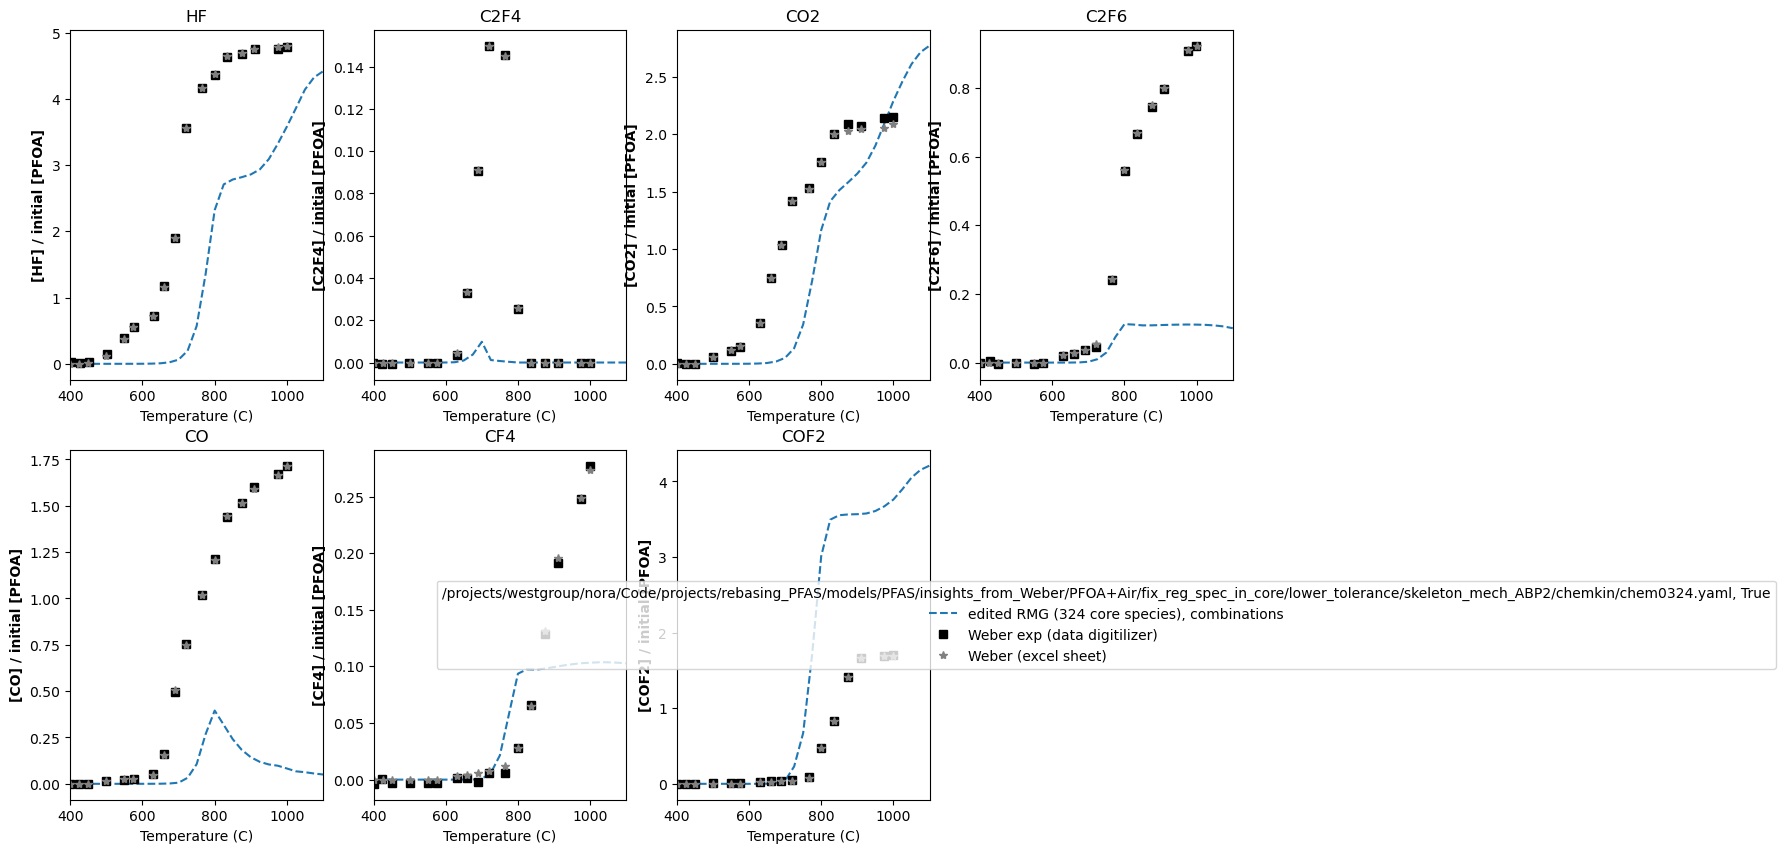

In [25]:
fig, axs = plt.subplots(2, 4, figsize=(15, 10))
# chemkins_to_convert=['317_edited']
# chemkins_to_convert=[317, '317_edited']
chemkins_to_convert = ['324_edited']

for ind, cn in enumerate(chemkins_to_convert): 
    for spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber):
        
        print(spc)

        #get plotting axis
        plotting_axis = axes_for_plotting[spc]


        #RMG mech at this chemkin number
        exit_concentrations, temps_to_plot = get_exit_concentration_ratio(results_for_all_chemkins[cn], spc)
        if 'edited' in str(cn): 
            label = f'edited RMG ({cn.replace('_edited', '')} core species), combinations'
            line_style = '--'
        if 'edited' not in str(cn): 
            label = f'RMG'
            line_style = '-'
        axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, line_style, color='tab:blue', label=label)
        # axs[plotting_axis[0], plotting_axis[1]].plot(nominal_temperatures, exit_concentrations, line_style, color='tab:orange', label=label)



        if ind==0: #only do this once
            
            #Weber mech using our simulation
            # exit_concentrations_weber, temps_to_plot = get_exit_concentration_ratio(results_for_weber['weber'], web_spc, weber=True)
            # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', label = 'Weber, simulated')
            
            #grab Weber experiment data that I pulled from his published plots via data digitilizer
            exp_data = get_experiment_data(exp_mapping[spc])
            experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])
            axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

            #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
            exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_150mLmin(exp_mapping[spc])
            axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, '*', c='gray', label = 'Weber (excel sheet)') 
         


            axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
            axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]', fontweight='bold')
            axs[plotting_axis[0], plotting_axis[1]].set_title(web_spc)
            axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title=f'{mechanism_file}, {edit_gas_flag}')

# plt.legend()
plt.show()
# fig.savefig('./model_results.pdf')-

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(15, 10))
# chemkins_to_convert=['317_edited']
# chemkins_to_convert=[317, '317_edited']
chemkins_to_convert = [300]

for ind, cn in enumerate(chemkins_to_convert): 
    for spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber):
        
        print(spc)

        #get plotting axis
        plotting_axis = axes_for_plotting[spc]


        #RMG mech at this chemkin number
        exit_concentrations, temps_to_plot = get_exit_concentration_ratio(results_for_all_chemkins[cn], spc)
        if 'edited' in str(cn): 
            label = f'edited RMG ({cn.replace('_edited', '')} core species), combinations'
            line_style = '--'
        if 'edited' not in str(cn): 
            label = f'RMG'
            line_style = '-'
        axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, line_style, color='tab:blue', label=label)
        # axs[plotting_axis[0], plotting_axis[1]].plot(nominal_temperatures, exit_concentrations, line_style, color='tab:orange', label=label)



        if ind==0: #only do this once
            
            #Weber mech using our simulation
            # exit_concentrations_weber, temps_to_plot = get_exit_concentration_ratio(results_for_weber['weber'], web_spc, weber=True)
            # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', label = 'Weber, simulated')
            
            #grab Weber experiment data that I pulled from his published plots via data digitilizer
            exp_data = get_experiment_data(exp_mapping[spc])
            experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])
            axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

            #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
            exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_150mLmin(exp_mapping[spc])
            axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, '*', c='gray', label = 'Weber (excel sheet)') 
         


            axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
            axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]', fontweight='bold')
            axs[plotting_axis[0], plotting_axis[1]].set_title(web_spc)
            axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title=f'{mechanism_file}, {edit_gas_flag}')

# plt.legend()
plt.show()
# fig.savefig('./model_results.pdf')-

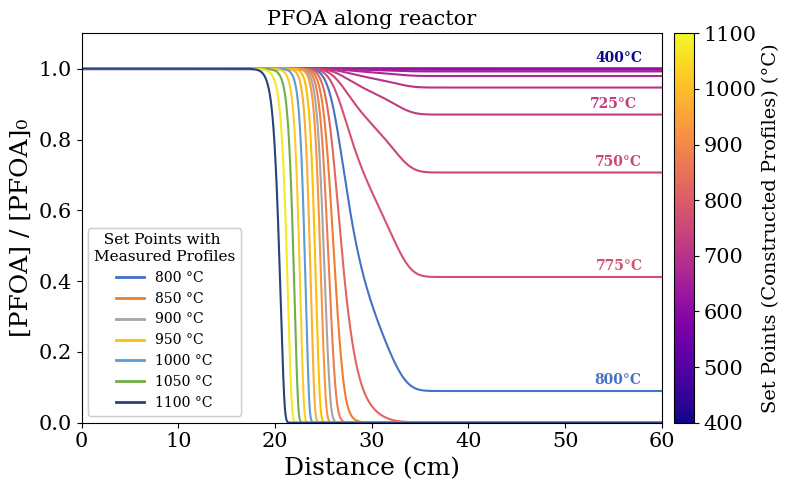

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.lines as mlines


plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['figure.autolayout'] = True
matplotlib.rcParams['font.family'] = 'serif'

def color_for_temperature(value, min_temp=400, max_temp=1100):
    color_map = plt.get_cmap('plasma')
    clipped_value = np.clip(value, min_temp, max_temp)
    normalized = (clipped_value - min_temp) / (max_temp - min_temp)
    return color_map(normalized)

    
cn = '324_edited'
#########
# --- Temperature profiles: imposed vs simulated ---
results = results_for_all_chemkins[cn]

rbg_colors = {800: (68, 114, 196), 
              850: (238, 125, 49), 
              900: (165, 165, 165), 
              950: (255, 192, 2), 
              1000: (91, 156, 213), 
              1050: (112, 174, 71), 
              1100: (38, 68, 121)}

label_these_lines = [400,725, 750, 775, 800]





fig, (ax2) = plt.subplots(1, figsize=(8, 5))

# # --- PFOA destruction ---
for nominal_T_C in nominal_temperatures:
    if nominal_T_C not in rbg_colors.keys():
        color = color_for_temperature(nominal_T_C)
    else: 
        color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])
    r = results[nominal_T_C]
    states = r['states']
    if 'PFOA(36)' in states.species_names:
        idx = states.species_index('PFOA(36)')
        X_PFOA = states.X[:, idx]
        # try:
        #     idx = states.species_index('PFOArot')
        #     X_PFOA += states.X[:, idx]
        # except ct.CanteraError:
        #     pass

        X_PFOA_0 = X_PFOA[0] if X_PFOA[0] > 0 else 4.02e-4


        y_vals = X_PFOA / X_PFOA_0
        x_vals = r['x'] * 100

        
        ax2.plot(r['x'] * 100, X_PFOA / X_PFOA_0, '-', color=color,
                 label=f'{nominal_T_C} °C')
        # ax2.plot(r['x'] * 100, X_PFOA / X_PFOA_0, '-',
        #          label=f'{nominal_T_C} °C')


    # --- Add inline label for constructed-profile (plasma) set points only ---
    if nominal_T_C in label_these_lines:
        #Find x-position where curve is still within plotted x-range (<=60 cm)
        mask = x_vals <= 60
        if np.any(mask):
            # Place label near the end of the visible curve, slightly above it
            label_x = x_vals[mask][-1]
            label_y = y_vals[mask][-1]
            ax2.annotate(f'{nominal_T_C}°C',
                         xy=(label_x, label_y),
                         xytext=(label_x - 2, label_y + 0.01),
                         color=color,
                         fontsize=10,
                         fontweight='bold',
                         ha='right',
                         va='bottom')





ax2.set_xlabel('Distance (cm)')
ax2.set_ylabel('[PFOA] / [PFOA]₀')
ax2.set_title('PFOA along reactor', fontsize = 15)
#ax2.legend()
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 1.1)
ax2.legend()


# --- Gradient colorbar legend (for plasma-colored temperatures) ---
plasma_temps = [T for T in nominal_temperatures if T not in rbg_colors]
if plasma_temps:
    norm = mcolors.Normalize(vmin=400, vmax=1100)
    sm = cm.ScalarMappable(cmap='plasma', norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax2, pad=0.02, fraction=0.046)
    cbar.set_label('Set Points (Constructed Profiles) (°C)', fontsize=14)
    # cbar.set_ticks(plasma_temps)

# --- Second legend for RGB-defined temperatures ---
rgb_handles = [
    mlines.Line2D([], [], color=tuple(c/255 for c in rgb), linewidth=2,
                  label=f'{T} °C')
    for T, rgb in rbg_colors.items()
    if T in nominal_temperatures
]
if rgb_handles:
    legend = ax2.legend(handles=rgb_handles, title='  Set Points with \nMeasured Profiles',
        loc='lower left',
        # bbox_to_anchor=(1.4, .6),  # anchor to bottom-right outside plot
        fontsize=10,
        title_fontsize=11,
        framealpha=0.9,
        bbox_transform=fig.transFigure)
    ax2.add_artist(legend)


plt.tight_layout()
plt.show()


#########

## HF concentration along the reactor
# plt.figure(figsize=(5, 3))
# ax = plt.gca()
# for nominal_T_C in nominal_temperatures:
#     color = color_for_temperature(nominal_T_C)
#     r = results[nominal_T_C]
#     states = r['states']
#     if 'HF(4)' in states.species_names:
#         idx = states.species_index('HF(4)')
#         X_HF = states.X[:, idx]
#         ax.plot(r['x'] * 100, X_HF, '-', color=color,
#                  label=f'{nominal_T_C} °C')
# ax.set_xlabel('Distance (cm)')
# ax.set_ylabel('Mole fraction of HF')
# ax.set_title('HF formation along reactor')
# #ax.legend()
# ax.set_xlim(0, 60)
# plt.tight_layout()
# plt.show()


###
# trying to pick out PFOA reactions that matter
#plot the concentration ratio results similar to Weber's figure 9 in publication

fig.savefig('../../../RMG_PFAS_paper/PFOA_along_reactor_skel_mech_AB2_324corespec.pdf')


In [14]:
# Flow conditions
Vdot = 50e-6 / 60.0  # volumetric flow rate: 150 mL/min -> m^3/s (at room T?)


chemkins_to_convert = [324] #number of core species in chemkin file name. 

# chemkins_to_convert = [435] #number of core species in chemkin file name. 


initial_composition_weber_50ml = {"PFOA": 4.67e-4, #467 ppm of PFOA at 50 ml/min volumetric flow
                    "H2O": 7.50e-4, #750 ppm of H2O(g) 
                    "O2": 0.20974442999999998, #Total of trace species: 4.67e-4 + 7.50e-4 = 0.001217, Remaining fraction for air: 1 - 0.001217 = 0.998783, 21% O2, 79% N2
                    "N2": 0.78903857,
                    }    

#### RMG mechanism ('/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech')
initial_composition_50ml ={"PFOA(36)": 4.67e-4, 
                    "H2O(8)": 7.50e-4, #750 ppm of H2O(g) 
                    "O2(5)": 0.20974442999999998, 
                    "N2": 0.78903857,
                    }


exclude_reactions_involving = None
exclude_species=['C5F11O2(3174)', 'O2(298)'] # 'O2(298)', 'C2F4O(3285)',] #'OO[C](F)F(2616)'] #(6234) + O2 reaction may be eating up a bit of O2? #['C4F10(2265)', 'C7HF13O(709)' ]
include_these_reactions = None

    
main_version = 'main' #'main_fg_in_XY_elim_hydroxyl' 
full_path_main = f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/just_PFAS/skeleton_mech_comparison_to_main/{main_version}/chemkin'
#for saving the data 
results_for_all_chemkins_50ml = {}
results_for_weber_50ml = {}

# for cn, edit_gas_flag in zip(chemkins_to_convert + [None], [False, False]): #run through all RMG chemkins we want, then do Weber's mech
for cn, edit_gas_flag in zip(chemkins_to_convert, [True]): #run through all RMG chemkins we want, then do Weber's mech
# for cn, edit_gas_flag in zip([None], [False]): #run through all RMG chemkins we want, then do Weber's mech

    if cn is not None: 
        weber_flag=False
    if cn is None: 
        weber_flag=True 
    
    if weber_flag==False: 
        #get the chemkin file name 
        if cn >= 100: 
            yaml_file_name = f'./chemkin/chem0{cn}_manually_edited.yaml'
            # yaml_file_name = f'chem0{cn}.yaml'
            # yaml_file_name = f'{full_path_main}/chem0{cn}.yaml'
        if cn < 100:
            # yaml_file_name = f'chem00{cn}.yaml'
            yaml_file_name = f'{full_path_main}/chem00{cn}.yaml'
        # mechanism_file = f'./chemkin/{yaml_file_name}'
        #mechanism_file = yaml_file_name
        mechanism_file =f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0{cn}.yaml' 
        print(mechanism_file)
        
        #or just directly define the mech file name
         # mechanism_file = <path_to_mech_file>
        print(f'******** Chemkin # {cn} ************')
    
    if weber_flag==True: 
        mechanism_file = '../../../../chemkin_for_Weber_2025_12_12/PFAS_O2_H2O_N2O_publish.yaml'
        print(f'******** Weber mech ************')
    
    print(mechanism_file)
    results = {}
    

    gas_full = ct.Solution(mechanism_file)
    print('Loaded gas_full')

    if edit_gas_flag==False: 
        gas = gas_full #there will be no editing of the Cantera gas object
        print('not editing gas')
    if edit_gas_flag==True:
        gas = edit_the_gas(gas_full, include_these_reactions = include_these_reactions, exclude_species=exclude_species, exclude_reactions_involving = exclude_reactions_involving)
        cn = str(cn)+'_edited' 
        print('using edited gas...')

    if weber_flag==False: 
        #we are dealing with the RMG mechanism 
        print('gas loaded successfully.')
        init_comp = initial_composition_50ml


    if weber_flag==True: 
        #we are dealing with the Weber mechanism
        print('gas loaded successfully.')
        init_comp = initial_composition_weber_50ml

    gas.TPX = 298.15, ct.one_atm, init_comp
    rho_inlet = gas.density
    mass_flow_rate = rho_inlet * Vdot


    for nominal_T_C in nominal_temperatures:
    
            
        print(f"\n{'='*60}")
        print(f"Simulating nominal temperature: {nominal_T_C} °C")
        print(f"{'='*60}")

        # Set up the gas at inlet conditions
        T_inlet_K = T_profile_K(0.0, nominal_T_C)
        gas.TPX = T_inlet_K, ct.one_atm, init_comp

        print(f'Vdot: {Vdot}')
        print(f"  Inlet T: {T_inlet_K:.1f} K ({T_inlet_K - 273.15:.1f} °C)")
        print(f"  Mass flow rate: {mass_flow_rate:.6e} kg/s")
        print(f"  Inlet velocity (at 298.15K): {Vdot / cross_area:.4f} m/s")
        print(f"  Inlet velocity (at T_inlet): {mass_flow_rate / (gas.density * cross_area):.4f} m/s")

        # Create the extensible reactor
        reactor = PFR_Reactor(
            gas, clone=True,
            nominal_temp_C=nominal_T_C,
            mass_flow_rate=mass_flow_rate,
            cross_section_area=cross_area,
        )

        # Create reactor network
        sim = ct.ReactorNet([reactor])    


        # preconditioner -  seems to work, to speed the solver up!
        sim.derivative_settings = {"skip-third-bodies":True, "skip-falloff":True}
        sim.preconditioner = ct.AdaptivePreconditioner()
        print('Starting to initialize simulation.')
        sim.initialize()
        print('Finished initializing simulation.')

        
        # Storage for results (adaptive number of points)
        t_values = []
        x_values = []
        T_values = []
        rop = []
        concentrations = []
        states = ct.SolutionArray(reactor.phase)


        # Integrate
        n = 0
        hit_solver_error = False
        while reactor.position < length:
            n += 1
            try:
                sim.step()
            except ct.CanteraError as e:
                hit_solver_error = True
                print(f"  Error occurred at step {n}: {e}")
                m = re.search(r"Components with largest weighted error estimates:\n(\d+).*\n(\d+).*\n(\d+)", str(e))
                if m:
                    print(f"  Problematic components: {m.group(1)}, {m.group(2)}, {m.group(3)}")
                    print(sim.component_name(int(m.group(1))))
                    print(sim.component_name(int(m.group(2))))
                    print(sim.component_name(int(m.group(3))))
                    if len(states) > 0:
                        try: 
                            last_good_state = states[-1]
                            find_culprit_reactions(last_good_state, species_index=int(m.group(1))-1)
                            find_culprit_reactions(last_good_state, species_index=int(m.group(2))-1)
                            find_culprit_reactions(last_good_state, species_index=int(m.group(3))-1)
                            #plot_rates_of_progress(last_good_state)
                        except IndexError: 
                            pass
                break

            t_values.append(sim.time)
            x_values.append(reactor.position)
            T_values.append(reactor.phase.T)
            states.append(reactor.phase.state)
            concentrations.append(reactor.phase.concentrations)
            rop.append(reactor.kinetics.net_rates_of_progress)
            
     

        if hit_solver_error:
            print(f"  Final position before failure: x = {reactor.position:.4f} m (target: {length:.4f} m)")
        else:
            time_at_end_of_reactor = sim.time
            print(f"  Reached end of reactor at step {n}, "
                  f"t = {sim.time:.6f} s, x = {reactor.position:.4f} m")
            
        

        results[nominal_T_C] = {
            't': np.array(t_values),
            'x': np.array(x_values),
            'T': np.array(T_values),
            'states': states,
        }

    if weber_flag==False: 
        results_for_all_chemkins_50ml[cn] = results
    if weber_flag==True: 
        results_for_weber_50ml['weber'] = results
        


/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0324.yaml
******** Chemkin # 324 ************
/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0324.yaml
Loaded gas_full
excluding species O2(298)
excluding species C5F11O2(3174)
Gas (full) previously had 6407 reactions.
Includes excluded species, removing: C2F4(64) + C3F7O2(837) <=> C5F11O2(3174).
Includes excluded species, removing: C5F11O2(3174) <=> C2F4O(3285) + C3F7O(3048).
Includes excluded species, removing: O2(5) + OHr(7) <=> O2(298) + OHr(7).
Includes excluded species, removing: H(1) + O2(298) <=> HO2r(9).
Includes excluded species, removing: CHF2r(20) + O2(298) <=> CHF2OO(159).
Includes excluded species, removing: C6HF10O2(328) + O2(298) <=> C6HF10O4(754).
Includes excluded species, removing: H2O2(10) <=> 

/tmp/ipykernel_2139924/2629332373.py:175: DeprecationWarning: Reactor.kinetics: To be removed after Cantera 3.2. Renamed to `phase`.
  rop.append(reactor.kinetics.net_rates_of_progress)


  Reached end of reactor at step 2056, t = 23.428033 s, x = 0.6023 m

Simulating nominal temperature: 425 °C
Vdot: 8.333333333333333e-07
  Inlet T: 295.1 K (22.0 °C)
  Mass flow rate: 9.885528e-07 kg/s
  Inlet velocity (at 298.15K): 0.0217 m/s
  Inlet velocity (at T_inlet): 0.0214 m/s
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 722, t = 23.174024 s, x = 0.6005 m

Simulating nominal temperature: 450 °C
Vdot: 8.333333333333333e-07
  Inlet T: 295.1 K (22.0 °C)
  Mass flow rate: 9.885528e-07 kg/s
  Inlet velocity (at 298.15K): 0.0217 m/s
  Inlet velocity (at T_inlet): 0.0214 m/s
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 831, t = 23.012181 s, x = 0.6008 m

Simulating nominal temperature: 475 °C
Vdot: 8.333333333333333e-07
  Inlet T: 295.3 K (22.1 °C)
  Mass flow rate: 9.885528e-07 kg/s
  Inlet velocity (at 298.15K): 0.0217 m/s
  Inlet velocity (at T_inlet): 0.0214 m/s
Starti

HF(11)
C2F4(64)
CO2(13)
C2F6(51)
CO(12)
CF4(23)
COF2(25)


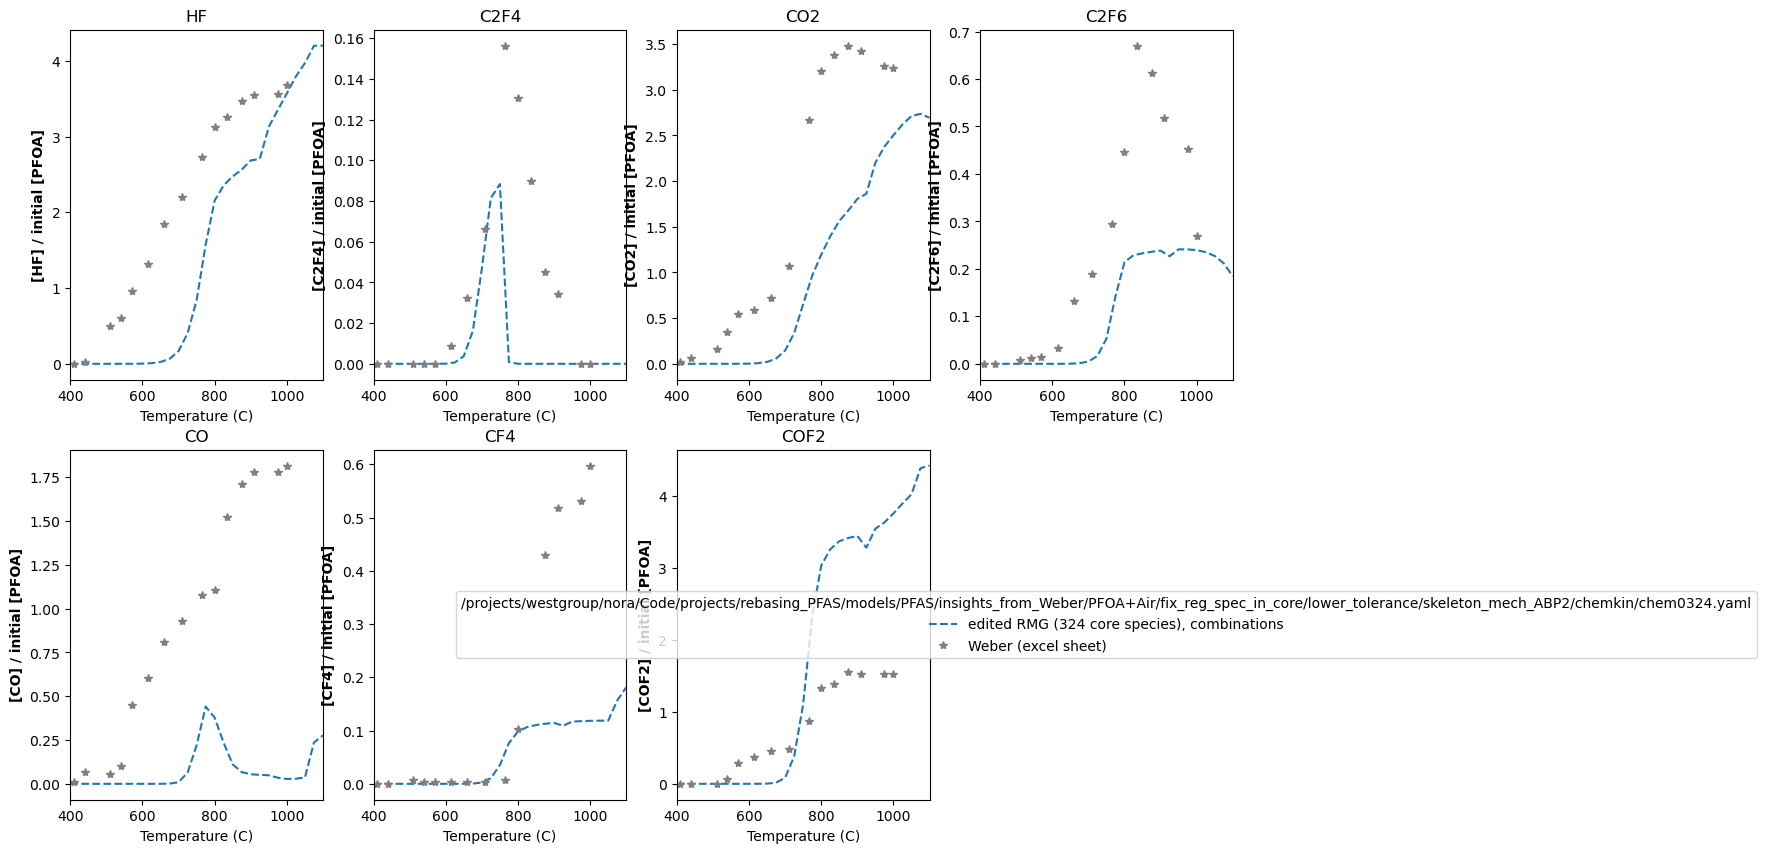

In [15]:
fig, axs = plt.subplots(2, 4, figsize=(15, 10))
chemkins_to_convert=['324_edited']
# chemkins_to_convert=[317]

for ind, cn in enumerate(chemkins_to_convert): 
    for spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber):
        
        print(spc)

        #get plotting axis
        plotting_axis = axes_for_plotting[spc]


        #RMG mech at this chemkin number
        exit_concentrations, nominal_temps_to_plot = get_exit_concentration_ratio(results_for_all_chemkins_50ml[cn], spc)
        if 'edited' in str(cn): 
            label = f'edited RMG ({cn.replace('_edited', '')} core species), combinations'
            line_style = '--'
        if 'edited' not in str(cn): 
            label = f'RMG'
            line_style = '-'
        axs[plotting_axis[0], plotting_axis[1]].plot(nominal_temps_to_plot, exit_concentrations, line_style, color='tab:blue', label=label)
        # axs[plotting_axis[0], plotting_axis[1]].plot(nominal_temperatures, exit_concentrations, line_style, color='tab:orange', label=label)



        if ind==0: #only do this once
            
            #Weber mech using our simulation
            # exit_concentrations_weber = get_exit_concentration_ratio(results_for_weber_50ml['weber'], web_spc, weber=True)
            # axs[plotting_axis[0], plotting_axis[1]].plot(nominal_temperatures, exit_concentrations_weber, ':', color='r', label = 'Weber, simulated')
            
            #grab Weber experiment data that I pulled from his published plots via data digitilizer
            # exp_data = get_experiment_data(exp_mapping[spc])
            # experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])
            # axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

            #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
            exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_50mLmin(exp_mapping[spc])
            axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, '*', c='gray', label = 'Weber (excel sheet)') 
         


            axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
            axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]', fontweight='bold')
            axs[plotting_axis[0], plotting_axis[1]].set_title(web_spc)
            axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title=mechanism_file)

# plt.legend()
plt.show()
# fig.savefig('./model_results.pdf')-

# SENSITIVITIES

In [11]:
#check to see at which meter depth down the PFR we are getting the sensitivities
z_data = np.linspace(0,60,500)

In [10]:
#mechanism_file = './chemkin/chem0317.yaml'
mechanism_file = '/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0324.yaml' 


In [12]:
for step_of_interest in list(range(0,250,50))[1:]+list(range(250,500,50))[1:]+[499]: 
    print(z_data[step_of_interest])

6.012024048096192
12.024048096192384
18.036072144288575
24.04809619238477
36.07214428857715
42.08416833667334
48.09619238476954
54.10821643286573
60.0


In [13]:
steps_of_interest = list(range(0,250,50))[1:]+list(range(250,500,50))[1:]+[499] #we are collecting sensitivity data at these steps
temp_of_interest = 800
for step in steps_of_interest: 
    print(z_data[step], (T_profile_K(z_data[step]/100, temp_of_interest)))

6.012024048096192 305.1839755660774
12.024048096192384 327.13404505625783
18.036072144288575 452.00953259761667
24.04809619238477 888.6475655976883
36.07214428857715 881.114213321527
42.08416833667334 446.31334665570796
48.09619238476954 326.3849314561824
54.10821643286573 304.9347279359911
60.0 297.5834474941038


In [14]:
for step in steps_of_interest[3:6]: 
    print(z_data[step], (T_profile_K(z_data[step]/100, temp_of_interest)))

24.04809619238477 888.6475655976883
36.07214428857715 881.114213321527
42.08416833667334 446.31334665570796


In [ ]:
temp_of_interest

In [ ]:
temp_of_interest = 850

z_data = np.linspace(0,60,500)


int_diam = 0.007 #in meters, experiments have a 7 mm ID in reactor
radius = int_diam/2
cross_area = np.pi*radius*radius #cross sectional area [m**2]
Vdot = 150e-6 / 60.0 #volumetric flow rate, 150 mL/min → m³/s
v0 = Vdot/cross_area #m/s, velocity in x direction 
length = 0.6 #in m, 60 cms
n_steps = len(z_data)
dz = length / n_steps 

print(f'Mech file: {mechanism_file}')   
gas_full = ct.Solution(mechanism_file)
print('Loaded gas_full')
gas = gas_full
# gas = edit_the_gas(gas_full, include_these_reactions = [], exclude_species=exclude_species, exclude_reactions_involving = exclude_reactions_involving)

states = ct.SolutionArray(gas, extra=['z', 'time', 'temp']) #for storing state information as we march through the reactor

#gas = edit_the_gas(gas_full, include_these_reactions = [],  exclude_reactions_involving=reactions_to_remove)
# gas = edit_the_gas(gas_full, include_these_reactions = include_these, exclude_species = exclude_species, exclude_reactions_involving=reactions_to_remove, multiplier = None)
#gas = edit_the_gas(gas_full, include_these_reactions = [], exclude_reactions_involving=[], multiplier = multiplier)
#gas = edit_the_gas(gas_full, include_these_reactions = include_these, exclude_reactions_involving=reactions_to_remove, exclude_species=exclude_species)
print('gas loaded successfully.')
print(f'length of gas.reactions() : {gas.n_reactions}')

gas.TPX = 300, ct.one_atm, initial_composition

sensitivity_data_per_step = {}
thermo_sensitivity_data_per_step = {}
steps_of_interest = list(range(0,250,50))[1:]+list(range(250,500,50))[1:]+[499] #we are collecting sensitivity data at these steps
    

time = 0 

    
for ind_z, z in enumerate(z_data):
    # inside this loop, z is in cm (but dz is still in m)

    collect_sensitivities=False
    sensitivity_data_900 = []
    thermo_sensitivity_900=[]
    

    #are we at a step where we should collect the sensitivities?
    if ind_z in [steps_of_interest[3]]:
        collect_sensitivities=True
        
    T_K = T_profile_K(z/100, temp_of_interest) #z is in cm, must convert to m 
    gas.TP = T_K, ct.one_atm
    tau = dz / v0  # residence time in this slice
    #r = ct.IdealGasConstPressureReactor(gas, energy='off')  #'off' = fixed T, because we are manually enforcing T
    r = ct.IdealGasReactor(gas, energy='off')  #'off' = fixed T, because we are manually enforcing T
    sim = ct.ReactorNet([r])


    if collect_sensitivities: 
        print(f'At current step of reactor to collect sensitivities: {z} cm ')
        for i in range(gas.n_reactions):
            r.add_sensitivity_reaction(i) #enable sensitivity with respect to the rates
            # set the tolerances for the solution and for the sensitivity coefficients
        for k in range(gas.n_species): 
            r.add_sensitivity_species_enthalpy(k)
        #print('finished adding sensitivities')
    sim.rtol = 1.0e-6
    sim.atol = 1.0e-15
    sim.rtol_sensitivity = 1.0e-6
    sim.atol_sensitivity = 1.0e-6

     
    try:
        time+=tau
        sim.advance(tau)
        # print(f'advancing simulation to {time} seconds.')
        if collect_sensitivities: 
            for i in range(gas.n_reactions):
                reaction_for_sens = gas.reactions()[i]
                try: 

                    sensitivity_to_HF = sim.sensitivity('HF(11)', i) #sensitivity of HF to reaction i 
                    sensitivity_to_C2F4 = sim.sensitivity('C2F4(64)', i) #C2F4
                    sensitivity_to_CO2 =  sim.sensitivity('CO2(13)', i) #CO2
                    sensitivity_to_C2F6 =  sim.sensitivity('C2F6(51)', i)   #C2F6, 
                    sensitivity_to_CO =  sim.sensitivity('CO(12)', i) #CO
                    sensitivity_to_CF4 = sim.sensitivity('CF4(23)', i) #CF4
                    sensitivity_to_COF2 = sim.sensitivity('COF2(25)', i)
                    sensitivity_to_CF2 = sim.sensitivity('CF2(s)(17)', i)
                    sensitivity_to_F = sim.sensitivity('F(3)', i)
                    sensitivity_to_FCO = sim.sensitivity('CFOr(24)', i)



                    sensitivity_data_900.append([sensitivity_to_HF, sensitivity_to_C2F4, sensitivity_to_CO2, sensitivity_to_C2F6, sensitivity_to_CO, sensitivity_to_CF4, sensitivity_to_COF2, sensitivity_to_CF2, sensitivity_to_F, sensitivity_to_FCO, r.kinetics.net_rates_of_progress[i], reaction_for_sens.equation]) #rates of progress in [kmol/m^3/s]
                except Exception as e: 
                    print(e)
                    sensitivity_data_900.append([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, reaction_for_sens.equation])

                
                    
            #num_ct_reactions = len(gas.reactions())
            # for k in range(gas.n_species): 
            #     spec_enthalpy_being_manipulated = gas.species()[k]
            #     #thermo_sensitivity[gas.species(k).name] = sim.sensitivity(gas.species(k).name, k + num_ct_reactions) #must increment by len of reactions because it was added in after add_sensitivity_reaction
            #     #https://github.com/ReactionMechanismGenerator/RMG-Py/blob/cf9e90efb90226645b4b6ac7b5f40d7757bd219c/rmgpy/tools/canteramodel.py#L511
            #     #I believe this is the "sensitivity of the state variables with respect to species k"
            #     thermo_sensitivity_HF = sim.sensitivity('HF(11)', k + num_ct_reactions) 
            #     thermo_sensitivity_C2F4 = sim.sensitivity('C2F4(64)', k + num_ct_reactions) 
            #     thermo_sensitivity_CO2 = sim.sensitivity('CO2(13)', k + num_ct_reactions)
            #     thermo_sensitivity_C2F6 = sim.sensitivity('C2F6(51)', k + num_ct_reactions)
            #     thermo_sensitivity_CO = sim.sensitivity('CO(12)', k + num_ct_reactions)
            #     thermo_sensitivity_CF4 = sim.sensitivity('CF4(23)', k + num_ct_reactions)
            #     thermo_sensitivity_COF2 = sim.sensitivity('COF2(25)', k + num_ct_reactions)
            #     thermo_sensitivity_CF2 = sim.sensitivity('CF2(s)(17)', k + num_ct_reactions)
            #     thermo_sensitivity_F = sim.sensitivity('F(3)', k + num_ct_reactions)
            #     thermo_sensitivity_FCO = sim.sensitivity('CFOr(24)', k + num_ct_reactions)


            #     thermo_sensitivity.append([thermo_sensitivity_HF, thermo_sensitivity_C2F4, thermo_sensitivity_CO2, thermo_sensitivity_C2F6, thermo_sensitivity_CO, thermo_sensitivity_CF4, thermo_sensitivity_COF2, thermo_sensitivity_CF2, thermo_sensitivity_F, thermo_sensitivity_FCO, spec_enthalpy_being_manipulated.name])
            
            #and add the sensitivitity data for this step to the larger dictionary
            if collect_sensitivities: 
                sensitivity_data_per_step[ind_z] = sensitivity_data_900
                thermo_sensitivity_data_per_step[ind_z] = thermo_sensitivity_900

       
    except ct.CanteraError as e:
        print(f"\nIntegration failed at z={z:.3f} m, T={T_K:.1f} K")
        print(f"Species with non-finite values: "
              f"{[s for s, X in zip(gas.species_names, r.thermo.X) if not np.isfinite(X)]}")
        states = ct.SolutionArray(r.phase)

        m = re.search(r"Components with largest weighted error estimates:\n(\d+).*\n(\d+).*\n(\d+)", str(e))
        if m:
            print(f"  Problematic components: {m.group(1)}, {m.group(2)}, {m.group(3)}")
            print(sim.component_name(int(m.group(1))))
            print(sim.component_name(int(m.group(2))))
            print(sim.component_name(int(m.group(3))))
            if len(states) > 0:
                try: 
                    last_good_state = states[-1]
                    find_culprit_reactions(last_good_state, species_index=int(m.group(1))-1)
                    find_culprit_reactions(last_good_state, species_index=int(m.group(2))-1)
                    find_culprit_reactions(last_good_state, species_index=int(m.group(3))-1)
                    #plot_rates_of_progress(last_good_state)
                except IndexError: 
                    pass
            break


        
        print(e)
        continue
 
        
    # states.append(r.thermo.state, z=z, time=time, temp=gas.T)
    #gas.TPX = T_K, ct.one_atm, r.thermo.X  # propagate composition only
    gas.X = r.thermo.X # propagate composition only


Mech file: /projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/fix_reg_spec_in_core/lower_tolerance/skeleton_mech_ABP2/chemkin/chem0324.yaml
Loaded gas_full
gas loaded successfully.
length of gas.reactions() : 6407


/tmp/ipykernel_2788010/4260987154.py:56: DeprecationWarning: ReactorBase.__init__: After Cantera 3.2, the default value of the `clone` argument will be `True`, resulting in an independent copy of the `phase` being created for use by this reactor. Add the `clone=False` argument to retain the old behavior of sharing `Solution` objects.
  r = ct.IdealGasReactor(gas, energy='off')  #'off' = fixed T, because we are manually enforcing T
/tmp/ipykernel_2788010/4260987154.py:160: DeprecationWarning: ReactorBase.thermo: To be removed after Cantera 3.2. Renamed to `phase`.
  gas.X = r.thermo.X # propagate composition only


In [ ]:
# 900 deg C sensitivities
lets_see = 'CO'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)
    FCO_sens_ranks = sorted(data, key=lambda x: abs(float(x[9])), reverse=True) 
    

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F', 
                        'FCO']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks, 
                        FCO_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    # equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    # print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


In [15]:
# 800 deg C sensitivities
lets_see = 'FCO'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)
    FCO_sens_ranks = sorted(data, key=lambda x: abs(float(x[9])), reverse=True) 
    

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F', 
                        'FCO']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks, 
                        FCO_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    # equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    # print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 800 FCO #######################
452.00953259761667

************* 18.036072144288575 cm *******************
0.5694855101022358 -8.012294520424416e-44 C2F4(64) + CFOr(24) <=> PF3acylFr(97)
0.5550144704287572 3.411383008211797e-19 PFOA(36) <=> HF(11) + PF8lactone(88)
0.5214477406168038 -9.205531075162606e-40 PF3acylFr(97) + PF4alkylr(110) <=> PF7acylF(50)
0.32779912116763643 -5.664234181476308e-44 CFOr(24) + PF6alkylr(112) <=> PF7acylF(50)
0.05873097837519182 -3.0511449260417587e-19 CO(12) + PF7acylF(50) <=> PF8lactone(88)
-0.05860308365557115 -3.6023402731634405e-20 C7F14(120) + CO2(13) <=> PF8lactone(88)
-2.7260170957625643e-05 3.7074032685335156e-48 CFOr(24) + O2(5) <=> CO(12) + [O]OF(297)
1.1874334141104316e-05 -2.0518361770481866e-48 CFOr(24) + PF8acid2r(128) <=> CO(12) + PFOA(36)
-9.481814152593681e-07 -1.289533642865968e-49 CO(12) + F(3) <=> CFOr(24)
5.552664563694111e-07 -9.594776928320214e-50 CFOr(24) + PF8acid5r(131) <=> CO(12) + PFOA(36)
5.263070629122162e-07 -9.09

In [16]:
# 800 deg C sensitivities
lets_see = 'CO'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)
    FCO_sens_ranks = sorted(data, key=lambda x: abs(float(x[9])), reverse=True) 
    

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F', 
                        'FCO']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks, 
                        FCO_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    # equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    # print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 800 CO #######################
452.00953259761667

************* 18.036072144288575 cm *******************
0.5198102030052933 3.411383008211797e-19 PFOA(36) <=> HF(11) + PF8lactone(88)
0.05509110012383622 -3.0511449260417587e-19 CO(12) + PF7acylF(50) <=> PF8lactone(88)
-0.05488229733705308 -3.6023402731634405e-20 C7F14(120) + CO2(13) <=> PF8lactone(88)
1.535307620052312e-09 2.208829692114174e-20 C7F14(120) + H2O(8) <=> C7H2F14O(547)
-1.5254932824366237e-09 -5.074353153817145e-28 C8F14O(428) <=> C7F14(120) + CO(12)
-8.025279488784482e-17 9.793620112672142e-27 C7F14(120) <=> PF7ene(69)
8.881616095712883e-24 2.710505431213761e-20 O2(298) <=> O2(5)
3.7555797248516963e-25 1.18605339171847e-31 HOCOr(14) <=> CO2(13) + H(1)
-2.4706930510523047e-25 1.1861017508822455e-31 PFOA(36) <=> HOCOr(14) + PF7alkylr(113)
2.639826197170721e-26 5.146606763477793e-29 PFOA(36) <=> PF2acidr(89) + PF6alkylr(112)
2.519888553189742e-27 2.2807572570841744e-27 PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)


# 1000 deg C sensitivities

In [32]:
lets_see = 'HF'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 1000 HF #######################
657.5956461060512

************* 18.036072144288575 cm *******************
0.3755915255025987 2.5261872531352485e-11 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
3.868864326054294e-05 2.60216280909104e-15 PFOA(36) <=> CO2(13) + HF(11) + PF7ene(69)
						 ['PFOA(36)', 'CO2(13)', 'HF(11)', 'PF7ene(69)']
6.779966683336627e-06 -5.650309497493479e-16 C7HF13O(712) + HF(11) <=> C7H2F14O(547)
						 ['C7HF13O(712)', 'HF(11)', 'C7H2F14O(547)']
7.506387186873852e-07 1.6351823432288814e-11 C7F14(120) + H2O(8) <=> C7H2F14O(547)
						 ['C7F14(120)', 'H2O(8)', 'C7H2F14O(547)']
-2.0021534417574147e-07 -4.080389093795504e-12 CO(12) + PF7acylF(50) <=> PF8lactone(88)
						 ['CO(12)', 'PF7acylF(50)', 'PF8lactone(88)']
2.0015554351521533e-07 -2.1181483780953334e-11 C7F14(120) + CO2(13) <=> PF8lactone(88)
						 ['C7F14(120)', 'CO2(13)', 'PF8lactone(88)']
-1.2863243792951954e-07 -3.685625012269351e-12 C8F14O(428) <=> C7F1

In [33]:
lets_see = 'CO'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 1000 CO #######################
657.5956461060512

************* 18.036072144288575 cm *******************
0.5148331679844539 -4.080389093795504e-12 CO(12) + PF7acylF(50) <=> PF8lactone(88)
						 ['CO(12)', 'PF7acylF(50)', 'PF8lactone(88)']
-0.5146429762675165 -2.1181483780953334e-11 C7F14(120) + CO2(13) <=> PF8lactone(88)
						 ['C7F14(120)', 'CO2(13)', 'PF8lactone(88)']
-0.3809938973580795 -3.685625012269351e-12 C8F14O(428) <=> C7F14(120) + CO(12)
						 ['C8F14O(428)', 'C7F14(120)', 'CO(12)']
0.2701461015379061 1.6351823432288814e-11 C7F14(120) + H2O(8) <=> C7H2F14O(547)
						 ['C7F14(120)', 'H2O(8)', 'C7H2F14O(547)']
0.16060302753970335 2.5261872531352485e-11 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
0.01802508968444851 1.0910506680532535e-12 C7F14(120) <=> PF7ene(69)
						 ['C7F14(120)', 'PF7ene(69)']
1.5960937866477124e-08 6.880321186621946e-15 PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)
						 ['PFOA(36)', 'PF3alkylr(109)

# 850 deg C sens

In [15]:
lets_see = 'C2F4'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    if 'C2F4(' in str(row[-1]): 
                        print(row[ind], row[-2], row[-1])
                        equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                        print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 C2F4 #######################
466.99523998756365

************* 18.036072144288575 cm *******************
933.9910005969034

************* 24.04809619238477 cm *******************
-0.18805487662104722 1.1842358287489285e-06 C2F4(64) + OHr(7) <=> C2HF4O(355)
						 ['C2F4(64)', 'OHr(7)', 'C2HF4O(355)']
-0.10023196260078376 6.295379711395634e-07 C2F4(64) + OHr(7) <=> CHF2r(20) + COF2(25)
						 ['C2F4(64)', 'OHr(7)', 'CHF2r(20)', 'COF2(25)']
-0.03323675484885818 3.8506515938698067e-07 C2F4(64) + OHr(7) <=> CF2(s)(17) + CF2OHr(26)
						 ['C2F4(64)', 'OHr(7)', 'CF2(s)(17)', 'CF2OHr(26)']
925.9354764994761

************* 36.07214428857715 cm *******************
-0.32284417121588693 1.5442497508497785e-10 C2F4(64) + OHr(7) <=> C2HF4O(355)
						 ['C2F4(64)', 'OHr(7)', 'C2HF4O(355)']
-0.17295696525597107 8.272954062607721e-11 C2F4(64) + OHr(7) <=> CHF2r(20) + COF2(25)
						 ['C2F4(64)', 'OHr(7)', 'CHF2r(20)', 'COF2(25)']
-0.10173549929565016 4.89148531750243e-11 C2F4(64) + OH

In [32]:
lets_see = 'CO'
n_max = 30

print(f'########### {temp_of_interest} {lets_see} #######################')
for z_step, data_ in sensitivity_data_per_step.items(): 

    print((T_profile_K(z_data[z_step]/100, temp_of_interest)))
     
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} cm *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 CO #######################
933.9910005969034

************* 24.04809619238477 cm *******************
-0.7836708082276681 2.831288470961492e-06 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
-0.2879238296739154 -6.96658686073856e-08 C4HF7(630) + PF2alkylr(108) <=> C6HF12(3914)
						 ['C4HF7(630)', 'PF2alkylr(108)', 'C6HF12(3914)']
-0.20441516959574732 2.2502804227267178e-07 C7HF14(393) <=> C7HF14(394)
						 ['C7HF14(393)', 'C7HF14(394)']
-0.16138190360121898 -1.3403215108018383e-07 C2F4(64) + C5HF10(2702) <=> C7HF14(2645)
						 ['C2F4(64)', 'C5HF10(2702)', 'C7HF14(2645)']
-0.15860915354851315 6.019648650962561e-07 C4HF8(339) <=> C4HF8(627)
						 ['C4HF8(339)', 'C4HF8(627)']
-0.13024322597217355 2.2405543407600209e-07 CF3r(19) + O(2) <=> COF2(25) + F(3)
						 ['CF3r(19)', 'O(2)', 'COF2(25)', 'F(3)']
-0.1260754011502852 -2.5450462262505906e-07 C4HF8(1368) <=> C4HF8(626)
						 ['C4HF8(1368)', 'C4HF8(626)']
-0.11511560800161631 4.2

In [33]:
lets_see = 'COF2'
n_max = 30
print(f'########### {temp_of_interest} {lets_see} #######################')

for z_step, data_ in sensitivity_data_per_step.items(): 
    
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} m *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 COF2 #######################

************* 24.04809619238477 m *******************
0.1322440246307869 1.184235849713031e-06 C2F4(64) + OHr(7) <=> C2HF4O(355)
						 ['C2F4(64)', 'OHr(7)', 'C2HF4O(355)']
0.10728391563217142 7.701615105823367e-07 PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)
						 ['PFOA(36)', 'PF3alkylr(109)', 'PF5acidr(92)']
-0.09769437923848295 4.299418202393458e-07 C8F14O(428) + OHr(7) <=> C8HF14O2(2385)
						 ['C8F14O(428)', 'OHr(7)', 'C8HF14O2(2385)']
0.09165522778715644 1.676742473732752e-07 CF3r(19) + O2(298) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(298)', 'CF3O(175)', 'O(2)']
0.08152515848548575 1.4915849295353482e-07 CF3r(19) + O2(5) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(5)', 'CF3O(175)', 'O(2)']
-0.07873029832987147 2.831288470961492e-06 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
-0.07860267309577527 4.29939957785419e-07 OHr(7) + PF7ene(69) <=> C7HF14O(563)
						 ['OHr(7)', 'PF7ene(69)', 'C7

In [34]:
lets_see = 'C2F6'
n_max = 15
print(f'########### {temp_of_interest} {lets_see} #######################')

for z_step, data_ in sensitivity_data_per_step.items(): 
    
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} m *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 C2F6 #######################

************* 24.04809619238477 m *******************
-0.07598750864777995 6.914528936000431e-07 PF3alkylr(109) <=> C3F7(299)
						 ['PF3alkylr(109)', 'C3F7(299)']
-0.05575254836593374 4.299418202393458e-07 C8F14O(428) + OHr(7) <=> C8HF14O2(2385)
						 ['C8F14O(428)', 'OHr(7)', 'C8HF14O2(2385)']
-0.05236497885129359 2.730919360199382e-07 C3F7(299) + CF3r(19) <=> C4F10(2265)
						 ['C3F7(299)', 'CF3r(19)', 'C4F10(2265)']
-0.03270263731769304 1.3119092709400012e-06 F(3) + H2O(8) <=> HF(11) + OHr(7)
						 ['F(3)', 'H2O(8)', 'HF(11)', 'OHr(7)']
-0.03146413093840079 2.4283911882434734e-07 2 PF2alkylr(108) <=> PF4alkane(53)
						 ['2', 'PF2alkylr(108)', 'PF4alkane(53)']
-0.03008751447800939 2.2405543407600209e-07 CF3r(19) + O(2) <=> COF2(25) + F(3)
						 ['CF3r(19)', 'O(2)', 'COF2(25)', 'F(3)']
-0.0262318016202663 1.676742473732752e-07 CF3r(19) + O2(298) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(298)', 'CF3O(175)', 'O(2)']
-0.02384424572

In [37]:
lets_see = 'HF'
n_max = 30
print(f'########### {temp_of_interest} {lets_see} #######################')

for z_step, data_ in sensitivity_data_per_step.items(): 
    
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} m *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                # if row[ind]>0:
                     # sens    #net_rate_of_prog #equation
                    # if 'HF(11)' in row[-1]:
                        print(row[ind], row[-2], row[-1])
                        equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                        print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 HF #######################

************* 24.04809619238477 m *******************
0.1617231385078848 2.831288470961492e-06 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
0.029530854073481463 1.676742473732752e-07 CF3r(19) + O2(298) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(298)', 'CF3O(175)', 'O(2)']
0.02626902602214475 1.4915849295353482e-07 CF3r(19) + O2(5) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(5)', 'CF3O(175)', 'O(2)']
0.025399505865539802 7.701615105823367e-07 PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)
						 ['PFOA(36)', 'PF3alkylr(109)', 'PF5acidr(92)']
-0.01802640015287051 4.299418202393458e-07 C8F14O(428) + OHr(7) <=> C8HF14O2(2385)
						 ['C8F14O(428)', 'OHr(7)', 'C8HF14O2(2385)']
0.017010055514889832 2.6009242016294737e-07 H(1) + O2(5) <=> O(2) + OHr(7)
						 ['H(1)', 'O2(5)', 'O(2)', 'OHr(7)']
-0.015946546432390348 4.0418694884632087e-07 H(1) + O2(5) (+M) <=> HO2r(9) (+M)
						 ['H(1)', 'O2(5)', '(+M)', 'HO2r

In [38]:
lets_see = 'CF4'
n_max = 30
print(f'########### {temp_of_interest} {lets_see} #######################')

for z_step, data_ in sensitivity_data_per_step.items(): 
    
    data = data_


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
                        
    rankings = [HF_sens_ranks,
                        C2F4_sens_ranks,
                        CO2_sens_ranks,
                        C2F6_sens_ranks,
                        CO_sens_ranks ,
                        CF4_sens_ranks,
                        COF2_sens_ranks, 
                        CF2_sens_ranks,
                        F_sens_ranks] 
    print(f'\n************* {z_data[z_step]} m *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            for row in ranking[:n_max]: 
                if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-2], row[-1])
                    equation_string_edited = row[-1].replace(' + ', ' ').replace(' <=> ', ' ')
                    print('\t\t\t\t\t\t', equation_string_edited.split(' '))
            


########### 850 CF4 #######################

************* 24.04809619238477 m *******************
-0.25113226320541704 -3.7169269312711915e-07 CO(12) + F(3) <=> CFOr(24)
						 ['CO(12)', 'F(3)', 'CFOr(24)']
-0.11192712202006402 2.2405543407600209e-07 CF3r(19) + O(2) <=> COF2(25) + F(3)
						 ['CF3r(19)', 'O(2)', 'COF2(25)', 'F(3)']
-0.07959777443990705 4.299418202393458e-07 C8F14O(428) + OHr(7) <=> C8HF14O2(2385)
						 ['C8F14O(428)', 'OHr(7)', 'C8HF14O2(2385)']
-0.06895113058641429 4.0418694884632087e-07 H(1) + O2(5) (+M) <=> HO2r(9) (+M)
						 ['H(1)', 'O2(5)', '(+M)', 'HO2r(9)', '(+M)']
-0.05698853185093015 2.630905639209678e-07 2 CF3r(19) <=> C2F6(51)
						 ['2', 'CF3r(19)', 'C2F6(51)']
-0.051908110569450536 7.664846219390031e-08 CFOr(24) + O2(5) <=> CO(12) + [O]OF(297)
						 ['CFOr(24)', 'O2(5)', 'CO(12)', '[O]OF(297)']
-0.0452801979511187 6.914528936000431e-07 PF3alkylr(109) <=> C3F7(299)
						 ['PF3alkylr(109)', 'C3F7(299)']
-0.03752063951625873 2.730919360199382e-07 C3F

In [39]:
#COMBINED
lets_see = 'HF'
n_max = 10
print(f'########### {temp_of_interest} combined #######################')

for z_step, data_ in sensitivity_data_per_step.items(): 
    
    data = data_

    #combined sensitivity
    combined_sens = []    


    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    species_of_focus = ['HF',
                        'C2F4',
                        'CO2',
                        'C2F6',
                        'CO',
                        'CF4',
                        'COF2', 
                        'CF2',
                        'F']
    

    for sens_data in HF_sens_ranks: #just using HF because it species of interest only dictates what its sorted by, but info is same in all
        final_sens = 0
        for ind, spec in enumerate(species_of_focus):
            final_sens+=abs(sens_data[ind])
        combined_sens.append((final_sens, sens_data[-1]))
    
    sorted_combined_sens = sorted(combined_sens, key=lambda x: x[0], reverse=True)    
    
    n=0
    print(f'\n************* {z_data[z_step]} m *******************')
    for (final_sensitivity, eq) in sorted_combined_sens:
        if n<n_max: 
            n+=1
            
            print(final_sensitivity, eq)
            equation_string_edited = eq.replace(' + ', ' ').replace(' <=> ', ' ')
            print('\t\t\t\t\t\t', equation_string_edited.split(' '))
    
        else:
            break  

########### 850 combined #######################

************* 24.04809619238477 m *******************
1.3714849520765418 PFOA(36) <=> HF(11) + PF8lactone(88)
						 ['PFOA(36)', 'HF(11)', 'PF8lactone(88)']
1.1317407202770227 F(3) + H2O(8) <=> HF(11) + OHr(7)
						 ['F(3)', 'H2O(8)', 'HF(11)', 'OHr(7)']
1.0748144889930955 PFOA(36) <=> PF3alkylr(109) + PF5acidr(92)
						 ['PFOA(36)', 'PF3alkylr(109)', 'PF5acidr(92)']
0.6881659076572748 CF3r(19) + O2(298) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(298)', 'CF3O(175)', 'O(2)']
0.6474833753046362 F(3) + PFOA(36) <=> HF(11) + PF8carboxylr(44)
						 ['F(3)', 'PFOA(36)', 'HF(11)', 'PF8carboxylr(44)']
0.6119289764487886 CF3r(19) + O2(5) <=> CF3O(175) + O(2)
						 ['CF3r(19)', 'O2(5)', 'CF3O(175)', 'O(2)']
0.5468600962481044 CF2(s)(17) + O(2) <=> CFOr(24) + F(3)
						 ['CF2(s)(17)', 'O(2)', 'CFOr(24)', 'F(3)']
0.5434914866319878 C2F4(64) + OHr(7) <=> CF2(s)(17) + CF2OHr(26)
						 ['C2F4(64)', 'OHr(7)', 'CF2(s)(17)', 'CF2OHr(26)']
0.5373

# Thermo Sensitivity

In [27]:
for step, thermo_sensitivity_data in thermo_sensitivity_data_per_step.items():


    # [thermo_sensitivity_HF, thermo_sensitivity_C2F4, thermo_sensitivity_CO2, thermo_sensitivity_C2F6, thermo_sensitivity_CO, thermo_sensitivity_CF4, thermo_sensitivity_COF2, thermo_sensitivity_CF2, thermo_sensitivity_F, spec_enthalpy_being_manipulated] = thermo_sensitivity_data


    data = thermo_sensitivity_data

    HF_sens_ranks = sorted(data, key=lambda x: abs(float(x[0])), reverse=True)
    C2F4_sens_ranks = sorted(data, key=lambda x: abs(float(x[1])), reverse=True) #this was mistakenly appended to the sensitivity data list as a tuple
    CO2_sens_ranks = sorted(data, key=lambda x: abs(float(x[2])), reverse=True)
    C2F6_sens_ranks = sorted(data, key=lambda x: abs(float(x[3])), reverse=True)
    CO_sens_ranks = sorted(data, key=lambda x: abs(float(x[4])), reverse=True)
    CF4_sens_ranks = sorted(data, key=lambda x: abs(float(x[5])), reverse=True)
    COF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[6])), reverse=True)
    CF2_sens_ranks = sorted(data, key=lambda x: abs(float(x[7])), reverse=True)
    F_sens_ranks = sorted(data, key=lambda x: abs(float(x[8])), reverse=True)

    rankings = [HF_sens_ranks,
                C2F4_sens_ranks,
                CO2_sens_ranks,
                C2F6_sens_ranks,
                CO_sens_ranks ,
                CF4_sens_ranks,
                COF2_sens_ranks, 
                CF2_sens_ranks,
                F_sens_ranks] 
    
    print(f'\n************* {z_data[step]} m *******************')
    for ind, (spec, ranking) in enumerate(zip(species_of_focus, rankings)):
        if spec==lets_see: 
            list_of_sensitive_species = []
            for row in ranking[:n_max]: 
                # if row[ind]<0:
                     # sens    #net_rate_of_prog #equation
                    print(row[ind], row[-1])
                    list_of_sensitive_species.append(row[-1])
            print(list_of_sensitive_species)
                


************* 18.036072144288575 m *******************
-1.2000451173410524e-19 HF(11)
1.2000451173410524e-19 C7H2F14O(547)
-1.2000451173410524e-19 C7HF13O(712)
3.197766808742134e-20 PF7acylF(50)
-3.197766808741871e-20 CO2(13)
3.1977668087418376e-20 CO(12)
-3.1977668087418376e-20 C7F14(120)
-1.1050108562468454e-22 O2(298)
-3.332749924587551e-23 O2(5)
4.661063333936407e-25 F(3)
['HF(11)', 'C7H2F14O(547)', 'C7HF13O(712)', 'PF7acylF(50)', 'CO2(13)', 'CO(12)', 'C7F14(120)', 'O2(298)', 'O2(5)', 'F(3)']

************* 24.04809619238477 m *******************
6.08329967791528e-09 O2(5)
-5.373174396672174e-09 O2(298)
-3.315738283674619e-09 CO(12)
-2.16539606604788e-09 F(3)
1.9933034386507995e-09 CFOr(24)
-1.7656781898273528e-09 PF4alkylr(110)
-1.4124195139125557e-09 CF2(s)(17)
1.2435808518880253e-09 PF7ene(69)
-1.2086805915452974e-09 PFallylr(103)
-1.0591463170127722e-09 CF3r(19)
['O2(5)', 'O2(298)', 'CO(12)', 'F(3)', 'CFOr(24)', 'PF4alkylr(110)', 'CF2(s)(17)', 'PF7ene(69)', 'PFallylr(103)', 'C